# Coverage Is Not Connectivity: New York's EV fast-charging network (final)

SSIE 641 final project: Joubin Zahiri Khameneh, Shamim Sharbaf, Zeinab Davoodmanesh.

This notebook walks through the results question by question. Every number comes from `scripts/run_all.py`,
which writes `results/tables/*.csv`, `results/figures/*.png` and `results/summary.json`. Set `RUN = True` to
rebuild everything (about three minutes). The analysis code lives in `src/evnet/`.

Changes from notebook v3 (`notebooks/ev_network_v3.ipynb`):
- Q3 uses a Steiner-tree heuristic (Takahashi & Matsuyama, 1980) with upper and lower bounds and an exact
  feasibility test, for two objectives (whole network, all city pairs), instead of the greedy search.
- Road distances re-queried from OSRM for all site pairs within 60 miles (data/derived/road_miles_pairs_le60.u16.gz);
  links to new stations use the measured detour factor 1.22 for those distances; 1.2 is kept as a sensitivity check.
- "Big or small" is answered by ports as well as degree.
- Population share corrected: places with 5,000+ people hold 76% of the state, not 92%.
- New: budget against the $175M NEVI allocation, winter range, NYC-excluded and access-capped coverage,
  October 2026 data check.

In [1]:
import json, subprocess, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RUN = False
if RUN:
    subprocess.run([sys.executable, str(ROOT / "scripts" / "run_all.py")], check=True)

TAB, FIG = ROOT / "results" / "tables", ROOT / "results" / "figures"
S = json.load(open(ROOT / "results" / "summary.json"))
pd.set_option("display.max_colwidth", 120)
def t(name): return pd.read_csv(TAB / name)
def f(name): display(Image(filename=str(FIG / name), width=850))

## 1. Data

stations: 755 | fast ports: 3408 | sites: 754 | CCS sites: 661
places >= 5000: 362 | people: 15312729 | share of NY population: 75.8%
NYC's share of population-weighted city pairs: 73%
candidate L1/L2 locations: 4756
distances: OSRM road network


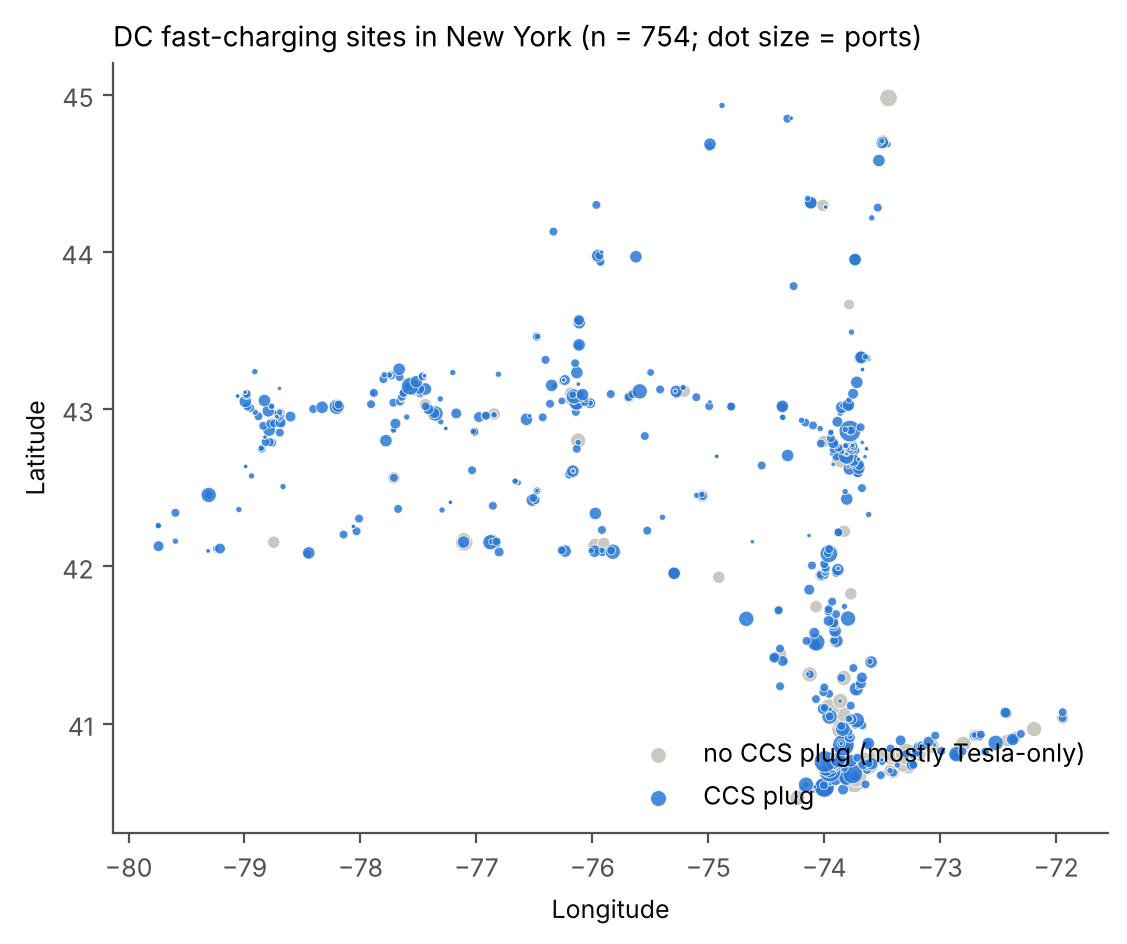

In [2]:
print("stations:", S["stations"], "| fast ports:", S["fast_ports"], "| sites:", S["sites"], "| CCS sites:", S["ccs_sites"])
print("places >= 5000:", S["places_5000"], "| people:", S["pop_places_5000"],
      f"| share of NY population: {S['share_state_pop_in_places_5000']:.1%}")
print(f"NYC's share of population-weighted city pairs: {S['nyc_share_of_pair_weight']:.0%}")
print("candidate L1/L2 locations:", S["candidates"])
print("distances:", S["distance_source"])
f("figS1_sites_map.png")

## 2. Q1: When does the network split?

The whole network is one piece from the longest link of its minimum spanning tree: 43.5 road miles.

{'all_road': 43.5, 'all_straight_x1.2': 43.1, 'all_straight_xfactor': 43.8, 'ccs_road': 43.5} | weakest link: Saranac Lake - Malone


,Unnamed: 0,all_road,all_road.1,all_road.2,all_straight_x1.2,all_straight_x1.2.1,all_straight_x1.2.2,all_straight_xfactor,all_straight_xfactor.1,all_straight_xfactor.2,ccs_road,ccs_road.1,ccs_road.2
0,NaN,miles,from,to,miles,from,to,miles,from,to,miles,from,to
1,0.0,43.5,Saranac Lake,Malone,43.11515633669068,Saranac Lake,Malone,43.83374227563553,Saranac Lake,Malone,43.5,Saranac Lake,Malone
2,1.0,37.15,Malone,Massena,33.85098158813832,Malone,Massena,34.41516461460729,Malone,Massena,37.15,Malone,Massena
3,2.0,34.65,Arkville,TANNERSVILLE,32.08966355076832,Pulaski,Watertown,32.62449127661446,Pulaski,Watertown,37.05,Warrensburg,Indian Lake
4,3.0,33.25,Chestertown,Indian Lake,30.290754956084065,Chestertown,Indian Lake,30.795600872018802,Chestertown,Indian Lake,36.05,Warrensburg,North Hudson
5,4.0,28.3,Pulaski,Watertown,26.32617712014979,Monticello,Roscoe,26.764946738818953,Monticello,Roscoe,34.65,Arkville,TANNERSVILLE
6,5.0,27.1,Monticello,Roscoe,25.878728398204327,Watertown,Cape Vincent,26.310040538174402,Watertown,Cape Vincent,30.85,Hancock,Afton
7,6.0,27.1,Elizabethtown,Lake Placid,25.86353361247827,Roscoe,Arkville,26.294592506019576,Roscoe,Arkville,28.3,Pulaski,Watertown


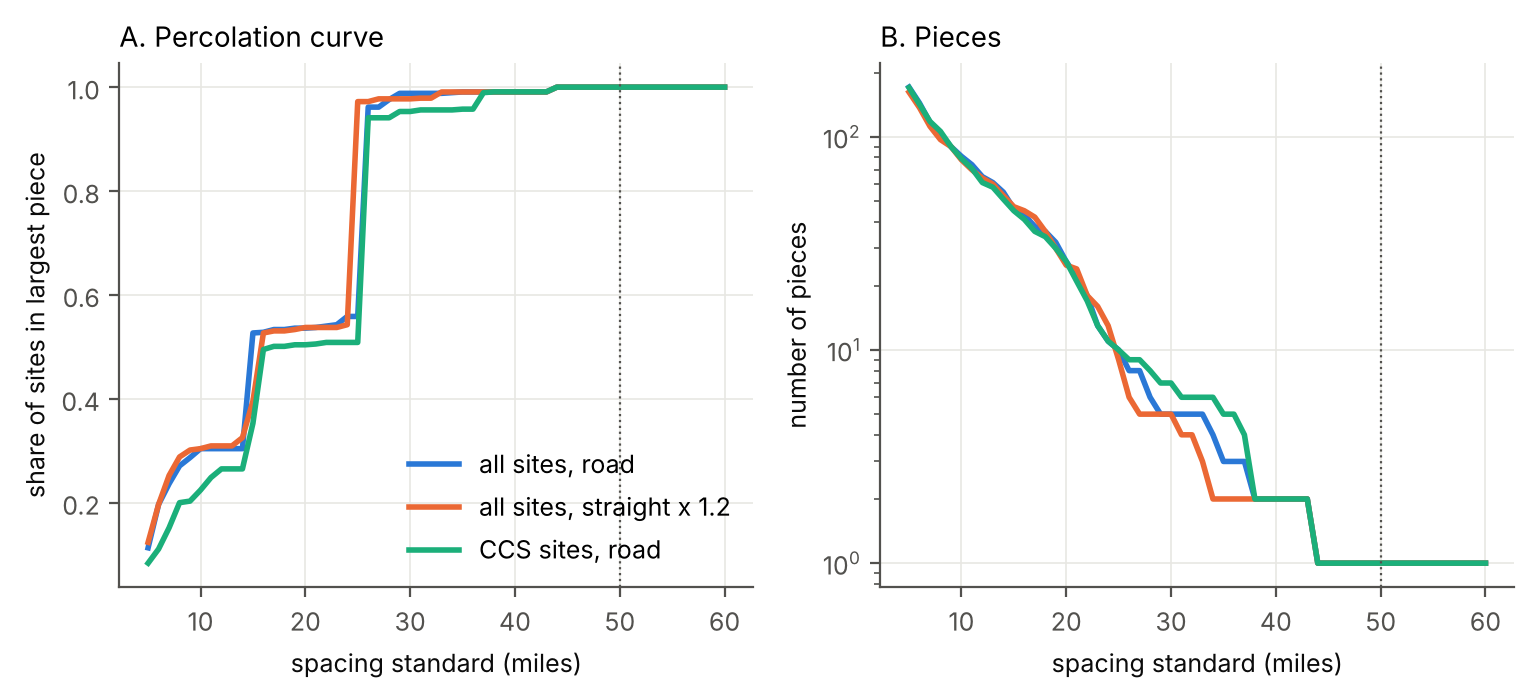

,piece,sites,mean_lat,mean_lon,main_cities
0,1,421,41.61,-73.70,"Queens, Albany, Brooklyn, New York, Latham, Riverhead"
1,2,294,42.85,-77.32,"Rochester, Syracuse, Buffalo, Niagara Falls, Yorkville, Elmira"
2,3,10,42.51,-75.09,"Oneonta, Cooperstown, Afton, Sidney"
3,4,9,44.02,-75.95,"Watertown, West Carthage, Cape Vincent, Alexandria Bay"
4,5,8,44.30,-74.04,"Lake Placid, Saranac Lake"
5,6,5,44.73,-74.97,"Potsdam, Massena"
6,7,2,41.96,-75.29,Hancock
7,8,2,44.85,-74.30,Malone
8,9,1,41.93,-74.91,Roscoe
9,10,1,42.16,-74.62,Arkville


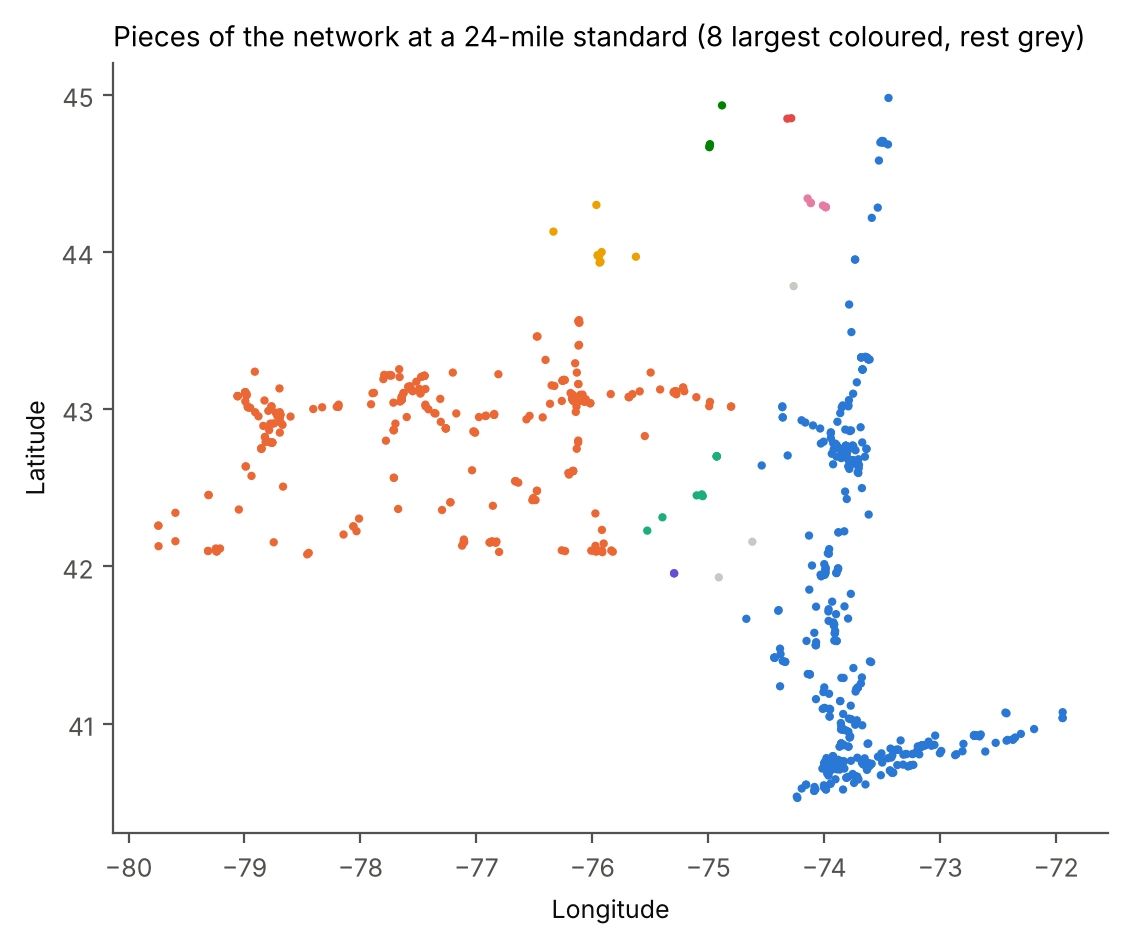

In [3]:
print({k: round(v, 1) for k, v in S["threshold"].items()}, "| weakest link:", S["weakest_link"])
display(t("q1_weakest_links.csv").head(8))
f("fig1_percolation.png")
display(t("q1_pieces_24mi.csv"))
f("fig2_pieces_24mi.png")

## 3. Q2: Which stations hold the network together?

Single points of failure (articulation points) are isolated rural sites: low degree, but typical or large by ports.

,network,miles,id,name,city,operator,degree,ports,sites_cut_off,degree_percentile,ports_percentile
0,all,30,712,"Chestertown, NY - Tesla Supercharger",Chestertown,Tesla,8,6,24,0.046419,0.701592
1,all,30,735,"Peru, NY - Tesla Supercharger",Peru,Tesla,12,8,11,0.108753,0.774536
2,all,30,724,Egglefield Bros,Elizabethtown,FORD_CHARGE,9,2,8,0.067639,0.270557
3,all,30,267,"Monticello, NY - Tesla Supercharger",Monticello,Tesla,9,12,3,0.067639,0.911141
4,all,30,279,"Roscoe, NY - Tesla Supercharger",Roscoe,Tesla,3,8,2,0.009284,0.774536
5,ccs,30,645,"Peru, NY - Tesla Supercharger",Peru,Tesla,11,8,9,0.114977,0.857791
6,ccs,30,290,Simmons Rockwell Ford Hornell NY,Hornell,RED_E,8,4,7,0.072617,0.497731
7,ccs,30,635,Egglefield Bros,Elizabethtown,FORD_CHARGE,8,2,7,0.072617,0.301059
8,all,35,712,"Chestertown, NY - Tesla Supercharger",Chestertown,Tesla,18,6,25,0.137931,0.701592
9,all,35,341,Thorpe's GMC,TANNERSVILLE,EV Connect,29,1,1,0.238727,0.000000


,miles,network,critical_sites,median_degree_all,median_degree_critical,median_ports_all,median_ports_critical,share_tesla_critical
0,25,all,13,42.0,6.0,4.0,4.0,0.230769
1,25,ccs,12,39.0,7.0,4.0,4.0,0.166667
2,30,all,5,50.0,9.0,4.0,8.0,0.800000
3,30,ccs,3,47.0,8.0,4.0,4.0,0.333333
4,35,all,2,58.0,23.5,4.0,3.5,0.500000
5,35,ccs,1,53.0,27.0,4.0,1.0,0.000000
6,40,all,0,66.0,NaN,4.0,NaN,NaN
7,40,ccs,1,62.0,23.0,4.0,2.0,0.000000
8,45,all,1,73.0,11.0,4.0,2.0,0.000000
9,45,ccs,2,68.0,17.0,4.0,2.0,0.000000


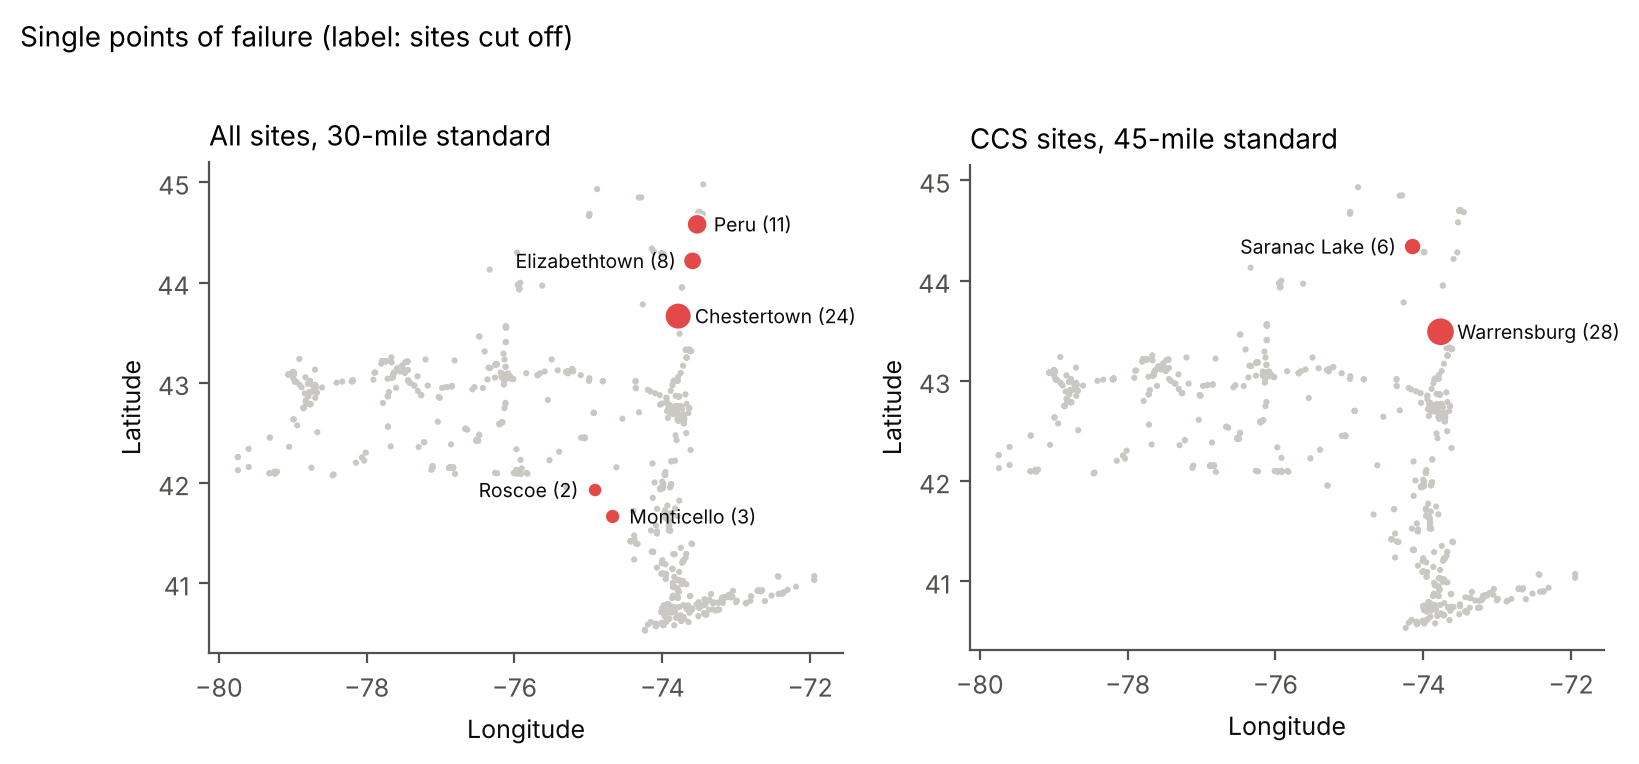

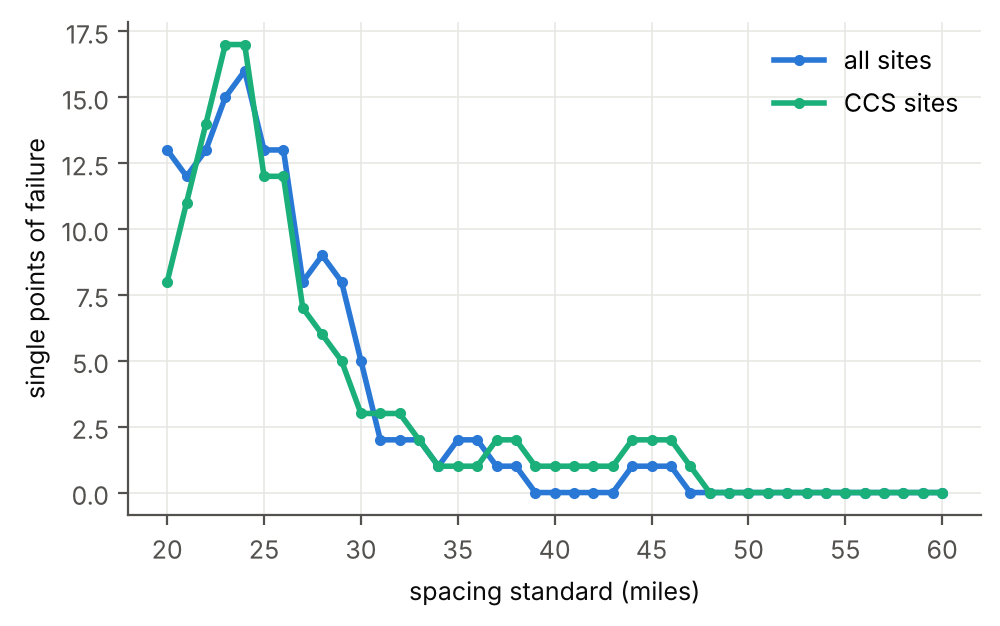

In [4]:
display(t("q2_critical_sites.csv"))
display(t("q2_big_or_small.csv"))
f("fig3_critical_sites.png")
f("figS2_cut_vertex_count.png")

### 3.1 Random failure and targeted attack

,network,miles,R_all,R_survivors,survivors_connected_p0.6
0,all,30,0.637763,0.886245,0.677311
1,all,35,0.671387,0.947352,0.829083
2,all,40,0.685032,0.973154,0.905590
3,all,45,0.693640,0.987376,0.953265
4,all,50,0.697674,0.994835,0.979504
5,ccs,30,0.616513,0.855934,0.678660
6,ccs,35,0.650161,0.915536,0.805406
7,ccs,40,0.678246,0.960794,0.897316
8,ccs,45,0.688513,0.979015,0.944126
9,ccs,50,0.696064,0.991766,0.967105


,miles,R_random,R_degree,R_betweenness,largest_after_15_betweenness,largest_after_30_betweenness,removals_to_drop_below_0.9
0,50,0.697674,0.695666,0.240167,0.980106,0.557029,17
1,30,0.637763,0.633370,0.148067,0.403183,0.295756,2


,degree,betweenness
0,Bronx,Schoharie
1,Bronx,Arkville
2,Bronx,Roscoe
3,The Bronx,Chittenango
4,The Bronx,New Baltimore
5,North New Hyde Park,Ravena
6,Jackson Heights,Little Falls
7,Queens,Little Falls
8,Roslyn Heights,Herkimer
9,Great Neck,Herkimer


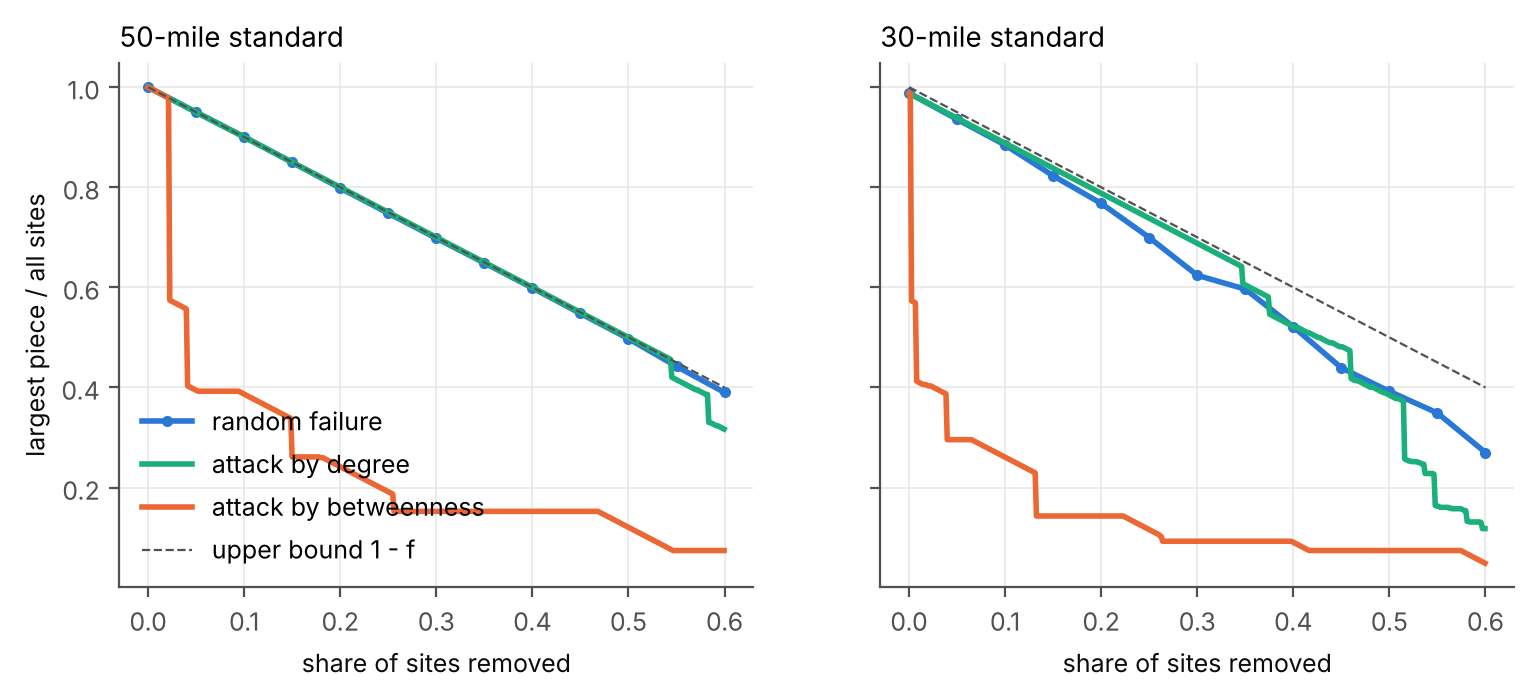

In [5]:
display(t("q2_random_failure.csv"))
display(t("q2_targeted_attack.csv"))
display(t("q2_attack_first15_50mi.csv"))
f("fig4_failure_attack.png")

### 3.2 Coverage is not connectivity

Coverage counts pairs of cities (362 places with 5,000+ people), plain and population-weighted, with two checks:
weights without New York City, and city access capped at 15 miles.

,miles,connectivity,coverage,coverage_weighted,coverage_weighted_excl_NYC,coverage_access15,coverage_weighted_access15
9,10,0.304,0.378,0.513,0.347,0.378,0.513
19,20,0.536,0.607,0.661,0.552,0.596,0.658
24,25,0.558,0.625,0.669,0.572,0.617,0.667
26,27,0.962,0.962,0.984,0.975,0.940,0.979
29,30,0.988,0.973,0.992,0.987,0.951,0.987
34,35,0.991,0.973,0.992,0.987,0.951,0.987
39,40,0.991,0.973,0.992,0.987,0.951,0.987
44,45,1.000,1.000,1.000,1.000,0.973,0.993
45,46,1.000,1.000,1.000,1.000,0.973,0.993
49,50,1.000,1.000,1.000,1.000,0.973,0.993


,name,pop,nearest
0,Ogdensburg city,10064,28.565587
1,Norwich city,7051,20.248668
2,Albion village,5637,18.325913
3,Medina village,6047,17.874881
4,Port Jervis city,8775,16.806188
5,Canton village,7155,11.960296
6,Hamlin CDP,5177,10.551793
7,Fort Drum CDP,15896,8.878025


,miles,name,city,coverage_lost,weighted_lost
0,30,"Chestertown, NY - Tesla Supercharger",Chestertown,0.005448,0.003864
1,30,"Peru, NY - Tesla Supercharger",Peru,0.005448,0.003864


,miles,R_random,R_degree,R_betweenness,Rw_random,Rw_degree,Rw_betweenness
0,50,0.994611,0.993631,0.471609,0.997945,0.994033,0.561526
1,30,0.898417,0.844714,0.366831,0.925452,0.876693,0.425114


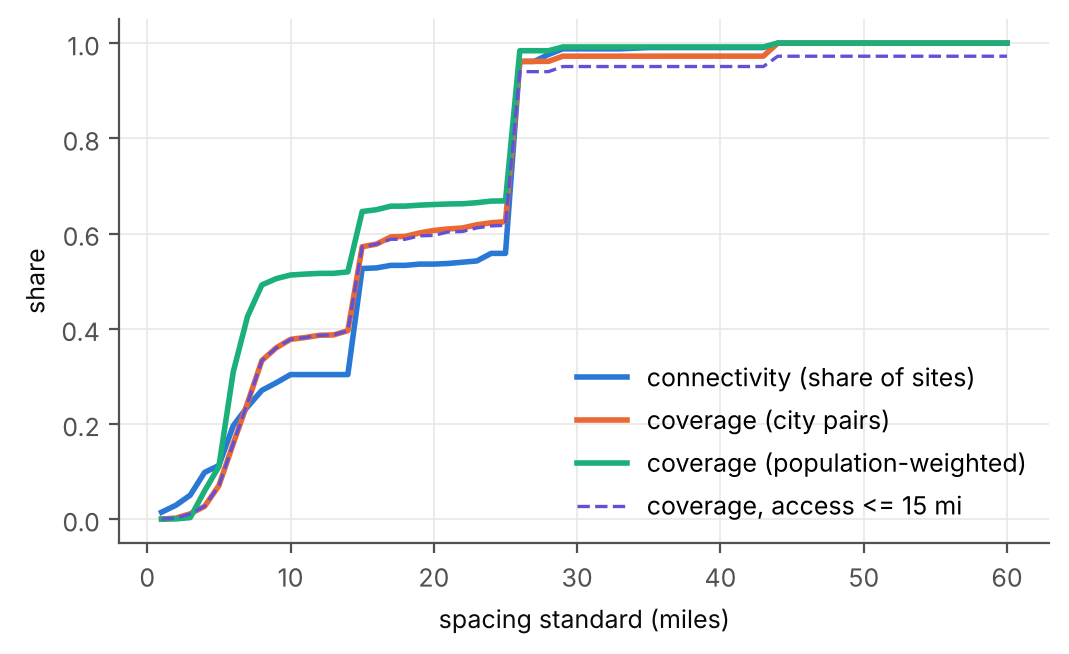

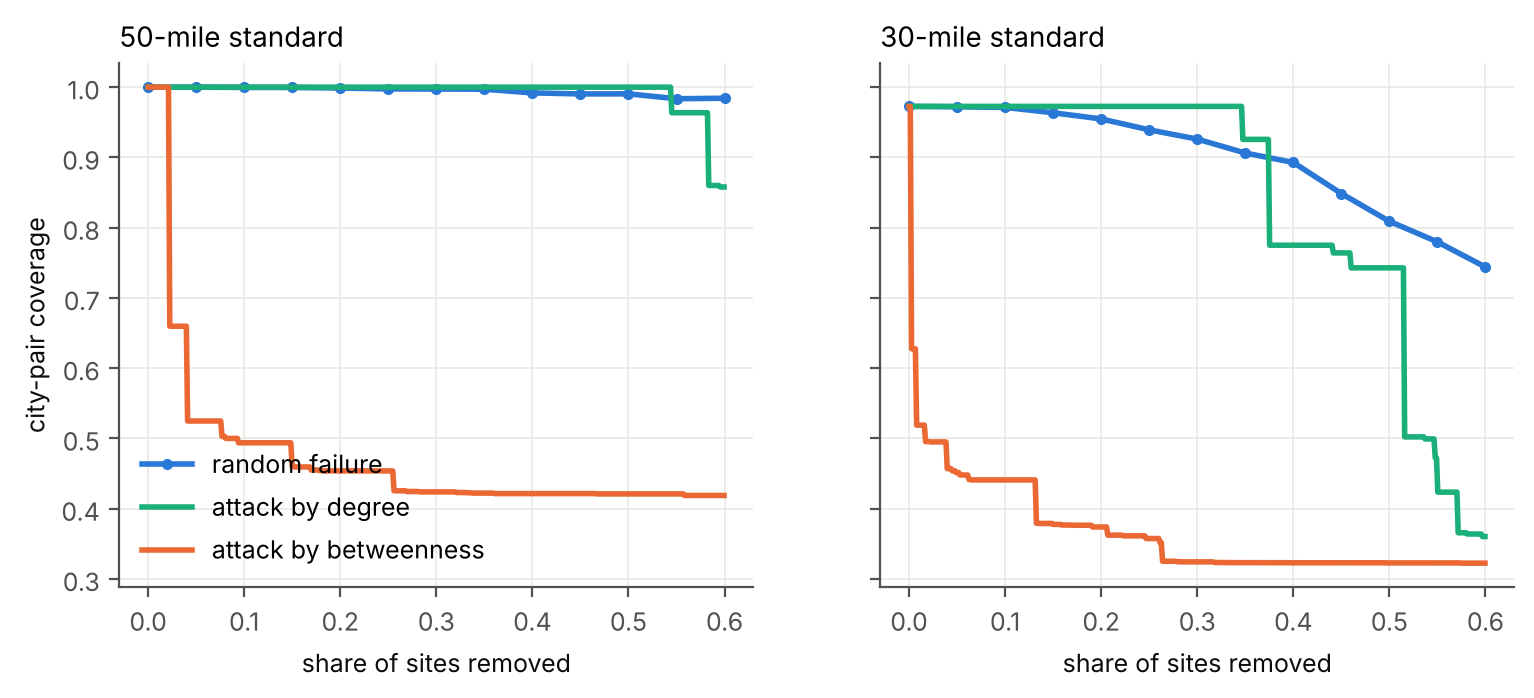

In [6]:
cv = t("coverage_curve.csv")
display(cv[cv["miles"].isin([10, 20, 25, 27, 30, 35, 40, 45, 46, 50])].round(3))
display(t("coverage_farthest_cities.csv"))
display(t("coverage_single_site_loss.csv"))
display(t("coverage_failure_attack.csv"))
f("fig5_coverage_curve.png")
f("figS3_coverage_attack.png")

## 4. Q3: How many new stations does each standard need, and can New York afford them?

`lower_bound` and `new_stations` bracket the true minimum for the whole-network objective. `feasible = False`
means some piece cannot be reached even if every candidate location were upgraded.

,objective,miles,pieces_before,lower_bound,new_stations,feasible,v3_greedy,where,unreachable
0,network,20,26,3.0,10,False,NaN,Neversink; Cherry Valley; Cattaraugus; Cortland; Shandaken; Olean; Mount Morris; Cooperstown; Sterling; North Creek,Afton; Alexandria Bay; Cape Vincent; Champlain; Elizabethtown; Hancock; Lake Placid; Lewis; Malone; Massena; North H...
1,network,25,10,4.0,8,False,NaN,Neversink; Downsville; Cherry Valley; Newcomb; Jay; Lowville; Turin; Boonville,Malone; Massena; Potsdam
2,network,30,5,1.0,2,False,NaN,Windham; Newcomb,Malone; Massena; Potsdam
3,network,35,3,2.0,2,True,NaN,Paul Smiths; Massena,NaN
4,network,40,2,1.0,1,True,NaN,Paul Smiths,NaN
5,network,45,1,0.0,0,True,NaN,NaN,NaN
6,network,50,1,0.0,0,True,NaN,NaN,NaN
7,coverage,20,26,NaN,7,False,8.0,Cherry Valley; Silver Creek; Earlville; Cooperstown; Cattaraugus; Cortland; Mount Morris,Canton village; Fort Drum CDP; Malone village; Massena village; Ogdensburg city; Plattsburgh city; Potsdam village; ...
8,coverage,25,10,NaN,4,False,4.0,Cherry Valley; Lowville; Turin; Boonville,Canton village; Malone village; Massena village; Ogdensburg city; Potsdam village
9,coverage,30,5,NaN,0,False,3.0,NaN,Canton village; Malone village; Massena village; Ogdensburg city; Potsdam village


,objective,miles,lower_bound,new_stations,feasible,where
0,network,20,3.0,10,False,Neversink; Cherry Valley; Cattaraugus; Cortland; Shandaken; Olean; Geneseo; Cooperstown; Sterling; North River
1,network,25,4.0,8,False,Neversink; Downsville; Cherry Valley; Newcomb; Jay; Lowville; Turin; Boonville
2,network,30,3.0,5,True,Windham; Newcomb; Canton; Gouverneur; Hogansburg
3,network,35,2.0,2,True,Paul Smiths; Massena
4,network,40,1.0,1,True,Ogdensburg
5,network,45,0.0,0,True,NaN
6,network,50,0.0,0,True,NaN
7,coverage,20,NaN,7,False,Cherry Valley; Silver Creek; Earlville; Cooperstown; Cattaraugus; Cortland; Geneseo
8,coverage,25,NaN,4,False,Cherry Valley; Lowville; Turin; Boonville
9,coverage,30,NaN,4,True,Gouverneur; Ogdensburg; Waddington; Hogansburg


cost_level,central,high,low
miles,,,
20,5.71,10.97,3.43
25,4.57,8.78,2.74
30,1.14,2.19,0.69
35,1.14,2.19,0.69
40,0.57,1.10,0.34
45,0.00,0.00,0.00
50,0.00,0.00,0.00


sites the $175M allocation could fund: {'low': 291, 'central': 175, 'high': 91}


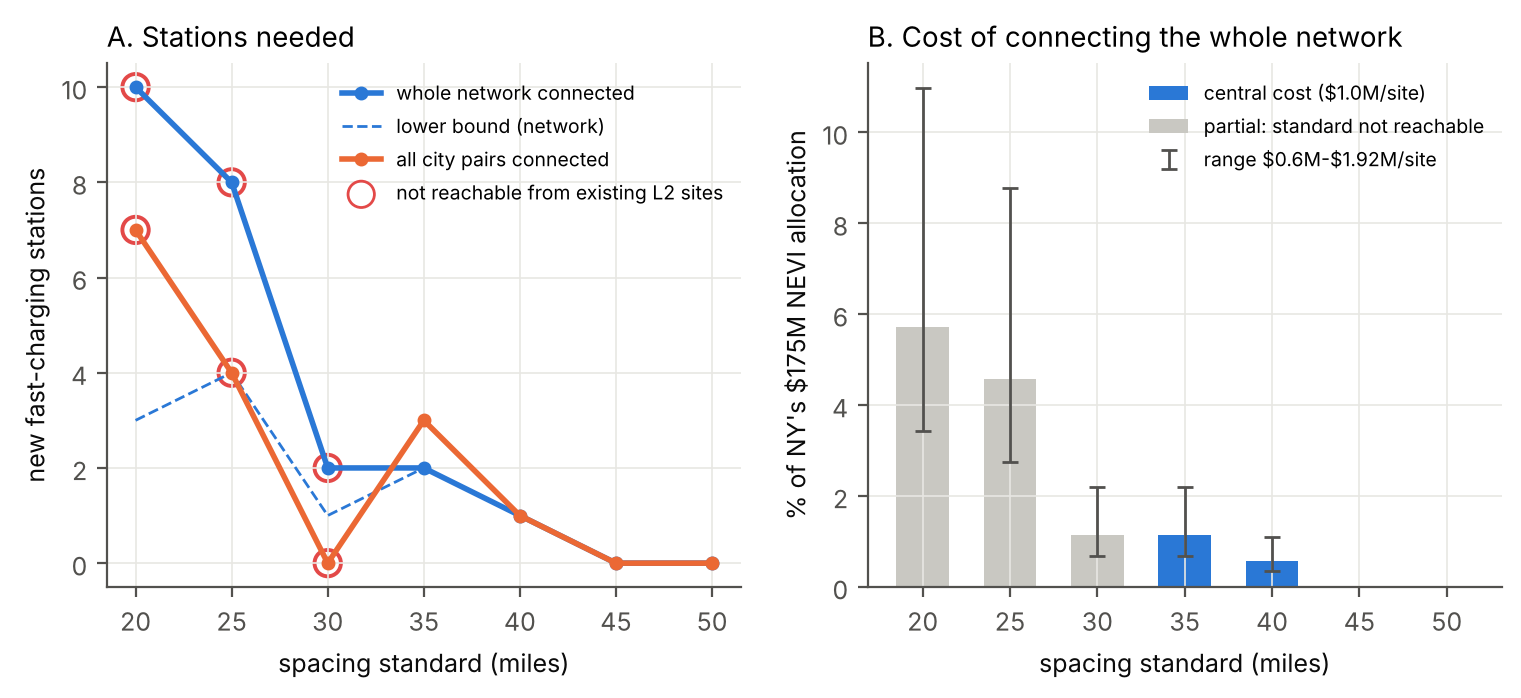

In [7]:
q3 = t("q3_cost_curve.csv")
display(q3)
display(t("q3_sensitivity_factor1.2.csv"))
b = t("q3_budget.csv")
display(b[b["objective"] == "network"].pivot(index="miles", columns="cost_level", values="share_of_NEVI_pct").round(2))
print("sites the $175M allocation could fund:", S["budget"]["sites_affordable"])
f("fig6_cost_curve.png")

### 4.1 Winter (41% range loss at 20°F with heat; AAA 2019)

nominal standard needed for one network in winter: 73.7 road miles


,nominal_miles,winter_effective_miles,pieces,connectivity,coverage,coverage_weighted
0,30,17.7,36,0.533156,0.593012,0.657506
1,35,20.7,23,0.537135,0.609587,0.662078
2,40,23.6,12,0.558355,0.622626,0.668198
3,45,26.6,8,0.961538,0.961709,0.984074
4,50,29.5,5,0.988064,0.972621,0.991970
5,55,32.5,5,0.988064,0.972621,0.991970
6,60,35.4,3,0.990716,0.972636,0.991971
7,65,38.4,2,0.990716,0.972682,0.991972
8,70,41.3,2,0.990716,0.972682,0.991972
9,75,44.3,1,1.000000,1.000000,1.000000


,nominal_miles,winter_effective_miles,pieces,lower_bound,new_stations,feasible,where
0,50,29.5,5,1,2,False,Windham; Newcomb
1,60,35.4,3,2,2,True,Paul Smiths; Massena
2,70,41.3,2,1,1,True,Ogdensburg


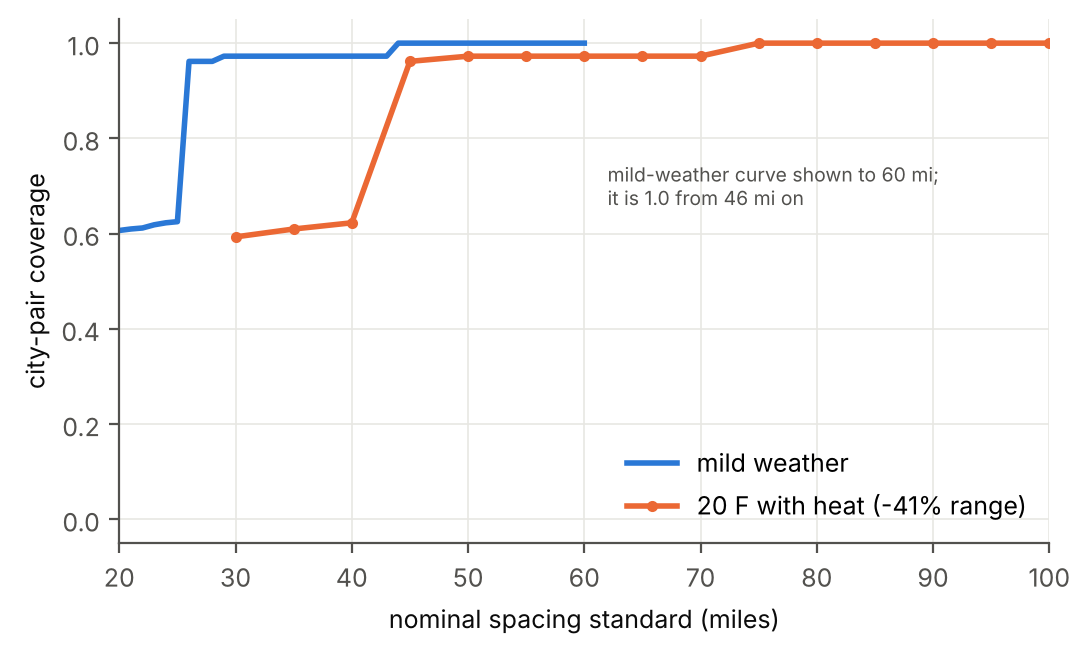

In [8]:
print(f"nominal standard needed for one network in winter: {S['winter_nominal_needed']:.1f} road miles")
display(t("winter.csv"))
display(t("winter_q3.csv"))
f("fig7_winter.png")

## 5. Control: is the network well sited?

,Unnamed: 0,real,random_mean,random_p05,random_p95,share_random_better
0,mst_threshold,43.834,45.096,36.560,53.921,0.43
1,coverage_30,0.962,0.770,0.599,0.956,0.02
2,coverage_40,0.973,0.971,0.956,1.000,0.43
3,weighted_coverage_30,0.984,0.809,0.654,0.980,0.02
4,cut_vertices_30,5.000,8.530,4.000,13.000,0.07
5,pieces_30,5.000,8.430,5.000,12.000,0.01


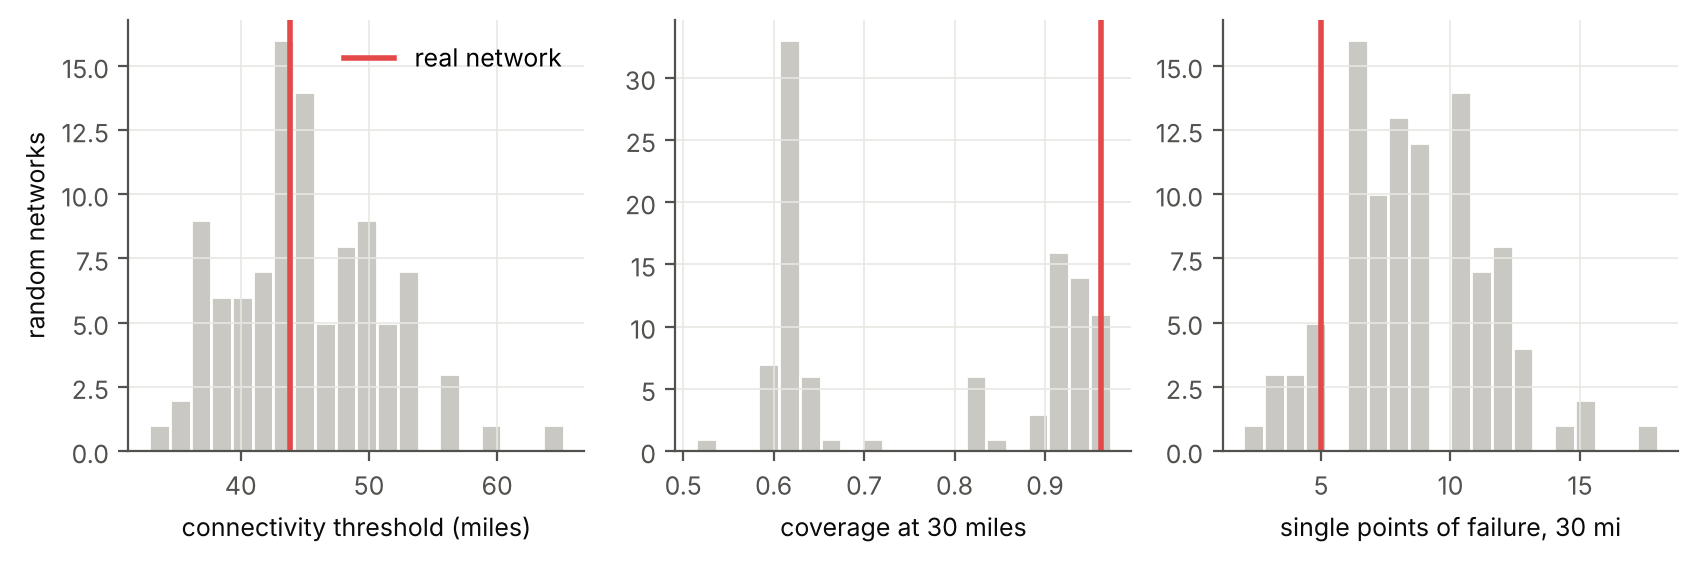

In [9]:
display(t("control_summary.csv").round(3))
f("fig8_control.png")

## 6. Robustness: October 13, 2026 station list

In [10]:
display(t("robustness_snapshot.csv"))

,snapshot,sites,threshold,weakest_link,cut_30,cut_35,cut_45,new_stations_30,new_stations_35,new_stations_40
0,"Sep 23, 2026",754,43.833742,Saranac Lake - Malone,Roscoe; Chestertown; Elizabethtown; Lewis; Peru,Chestertown; Malone; Massena,Saranac Lake,3,1,1
1,"Oct 13, 2026",793,43.833742,Saranac Lake - Malone,Roscoe; Chestertown; Lewis; Peru,Malone; Massena,Saranac Lake,3,1,1


## 6b. Extension (c): a second, lower-density state (Maine)

`scripts/run_maine.py` runs the same pipeline on Maine (DOE station export Nov 19, 2026; Census 2020 places;
OSRM road distances for all 7,626 site pairs) and compares it with New York.

,New York,Maine
fast-charging sites,754,124
"sites per 1,000 sq mi",16.0,4.0
threshold (road miles),43.5,151.2
weakest link,Saranac Lake - Malone,Medway - Van Buren
single points of failure at 30 mi,5,3
"R, betweenness attack at 50 mi",0.24,0.429
"R, random failure at 50 mi",0.698,0.639
new stations at 50 mi,0,6
new stations at 40 mi,1,5+ (infeasible)
new stations at 30 mi,2+ (infeasible),8+ (infeasible)


,miles,from,to
0,151.20,Medway,Van Buren
1,69.70,Baileyville,Lincoln
2,51.95,Newport,Greenville
3,49.20,Greenville,Jackman
4,42.70,Orono,Lincoln
5,40.50,Farmington,Rangeley


,miles,id,name,city,operator,degree,ports,sites_cut_off,degree_percentile,ports_percentile
0,30,78,Sundog FastCharge,Searsport,Non-Networked,12,4,4,0.225806,0.604839
1,30,47,11 Seahawk Ave Parking Lot,Brunswick,Non-Networked,22,4,1,0.508065,0.604839
2,30,116,"Medway, ME - Tesla Supercharger",Medway,Tesla,2,6,1,0.064516,0.758065
3,50,113,Thornton Brothers Inc Chrysler Dodge Jeep Ram,Lincoln,Non-Networked,13,2,2,0.112903,0.500000


,miles,R_random,R_degree,R_betweenness,removals_to_drop_below_0.9,first_8_betweenness
0,50,0.639448,0.553871,0.429355,3,Augusta; Augusta; Hallowell; Augusta; Augusta; Waterville; Fairfield; Fairfield
1,30,0.595329,0.537957,0.289462,0,Waterville; Fairfield; Fairfield; Oxford; Falmouth; Searsport; Topsham; Topsham


,objective,miles,pieces_before,lower_bound,new_stations,feasible,where,unreachable
0,network,20,18,5.0,10,False,Wiscasset; Buckfield; Woodstock; Wilton; Unity; Waldoboro; Damariscotta; Islesboro; Blue Hill; Bucksport,Baileyville; CALAIS; Greenville; Jackman; Lincoln; Medway; Millinocket; Rangeley; Van Buren
1,network,25,13,2.0,6,False,Damariscotta; Waldoboro; Unity; Bethel; Hampden; Farmington,Baileyville; CALAIS; Greenville; Jackman; Lincoln; Medway; Millinocket; Rangeley; Van Buren
2,network,30,7,4.0,8,False,Rangeley; Farmington; Monson; Dover-Foxcroft; Lubec; Machias; Milbridge; Hancock,Jackman; Lincoln; Medway; Millinocket; Van Buren
3,network,35,7,2.0,4,False,Carrabassett Valley; Dover-Foxcroft; Machias; Milbridge,Jackman; Lincoln; Medway; Millinocket; Van Buren
4,network,40,7,2.0,5,False,Carrabassett Valley; Old Town; Monson; Machias; Milbridge,Jackman; Van Buren
5,network,45,5,3.0,7,True,Monson; Jackman; Machias; Milbridge; Presque Isle; Houlton; Weston,NaN
6,network,50,4,3.0,6,True,Monson; Lubec; Milbridge; Presque Isle; Houlton; Weston,NaN
7,network,60,3,2.0,3,True,Weston; Caribou; Houlton,NaN
8,network,70,2,2.0,2,True,Limestone; Houlton,NaN
9,coverage,20,18,NaN,5,False,Waldoboro; Damariscotta; Wiscasset; Camden; Bucksport,Caribou city; Presque Isle city


,Unnamed: 0,real,random_mean,random_p05,random_p95,share_random_better
0,mst_threshold,131.641,86.140,60.908,131.662,0.95
1,coverage_30,0.873,0.843,0.616,0.875,0.72
2,coverage_40,0.875,0.875,0.875,0.875,0.00
3,weighted_coverage_30,0.928,0.899,0.675,0.928,0.72
4,cut_vertices_30,1.000,2.020,0.000,6.000,0.21
5,pieces_30,7.000,7.860,5.000,11.000,0.20


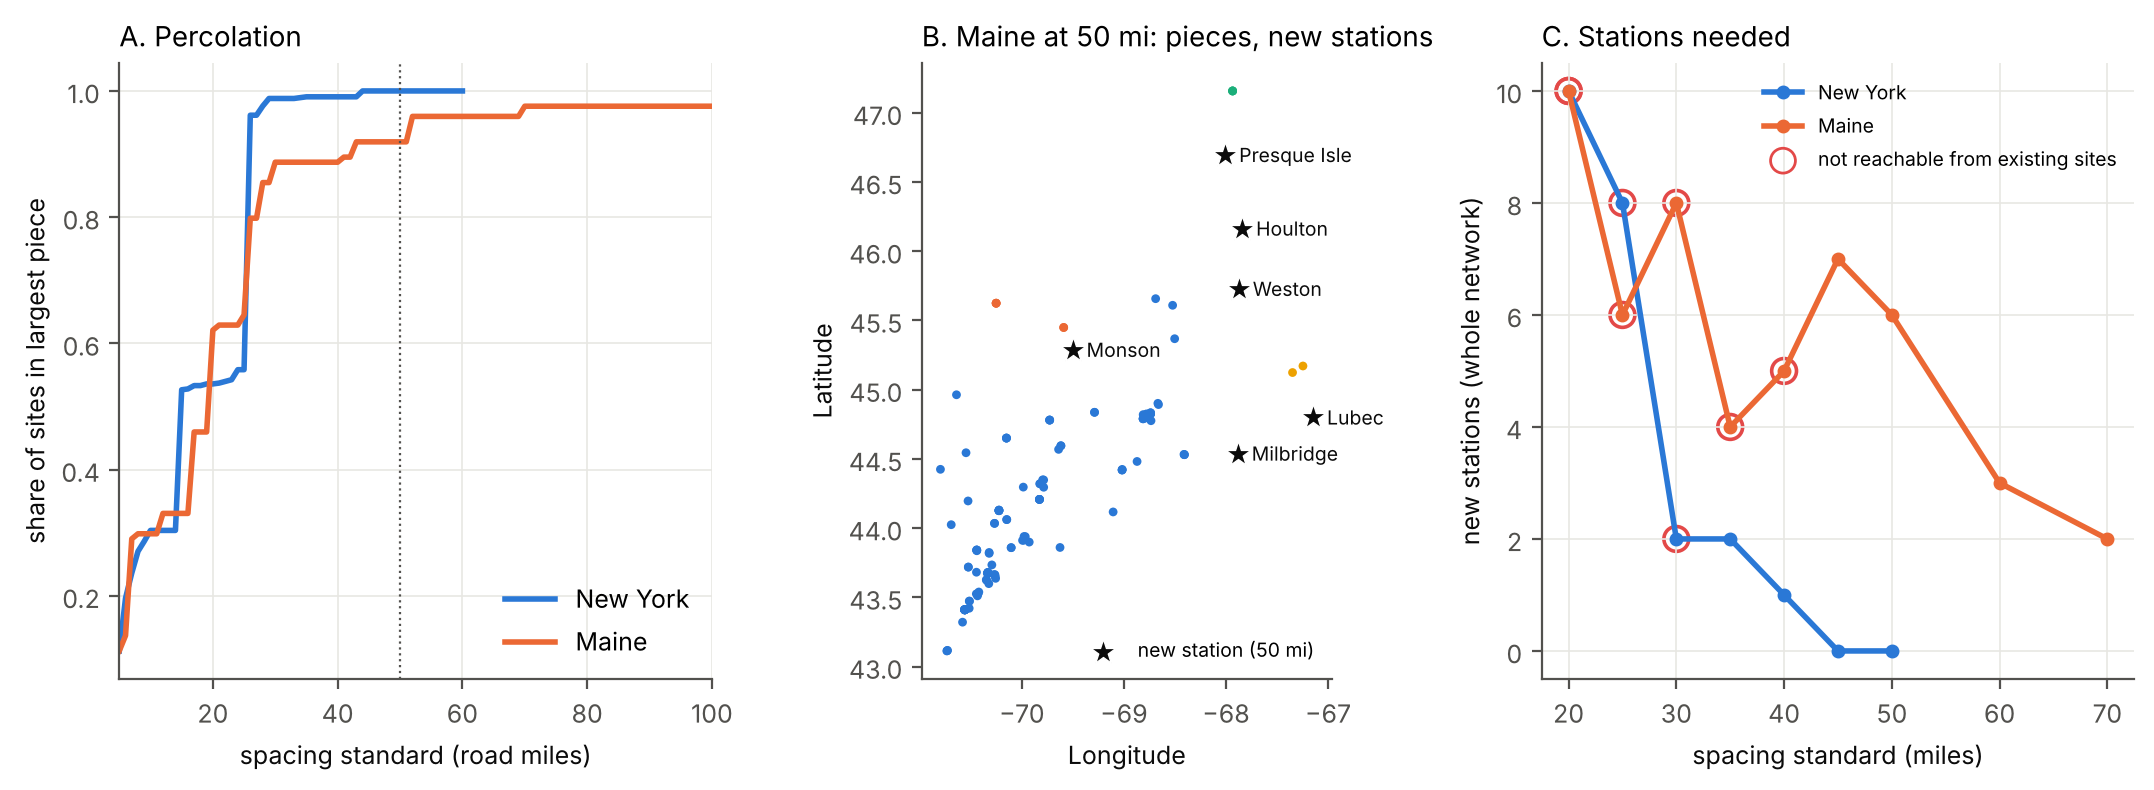

In [11]:
display(pd.read_csv(TAB / "ny_vs_maine.csv", index_col=0))
display(t("maine_weakest_links.csv").head(6))
display(t("maine_critical_sites.csv"))
display(t("maine_attack.csv"))
display(t("maine_q3_cost_curve.csv"))
display(t("maine_control_summary.csv").round(3))
f("fig9_maine.png")

## 7. Summary (OSRM road distances)

- **Q1.** One network from **43.5 road miles**; weakest link Saranac Lake – Malone, then Malone – Massena (37.2),
  Arkville – Tannersville (34.7) and Chestertown – Indian Lake (33.3). The two large regions join at 26 miles.
- **Q2.** At 30 miles five sites are single points of failure (Chestertown, Peru, Elizabethtown, Monticello, Roscoe),
  four of them Tesla Superchargers. They are isolated (median degree 9 vs 50), not small (median ports 8 vs 4).
  Betweenness attack: 17 removals (2.3%) cut the largest piece to 57% at 50 miles; at 30 miles the two Little Falls
  Thruway plazas alone do it. Degree attack does no more than random failure.
- **Coverage.** At 30–43 miles 99% of sites but 97.3% of city pairs are connected; every pair from 44 miles.
- **Q3.** 0 stations at 45–50 miles, 1 at 40 (Paul Smiths), 2 at 35 (Paul Smiths, Massena), all optimal, at most
  2.2% of the $175M NEVI allocation. 30 miles and below cannot be met from existing public charging locations
  (feasible at 30 with 5 if the new-link detour factor is 1.2 instead of the measured 1.22).
- **Winter.** One network needs a nominal 74 road miles; at 60 miles nominal two stations (Paul Smiths, Massena) suffice.
- **Control.** Better than 98% of 100 random networks at 30 miles; no better than chance on the overall threshold:
  the North Country gap is geographic.
- **Maine (extension c).** One piece only from 151 road miles (Medway – Van Buren); 6 new stations for 50 miles
  (19–60% of its $19.3M NEVI funds); 40 miles and below infeasible; critical sites again isolated, not small;
  sited worse than 95% of random networks from its own charging locations.